In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Question # 1 (Image Processing)

In [43]:
image_path = "/content/drive/MyDrive/Computer Vision/rabbit.jpg"

In [44]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

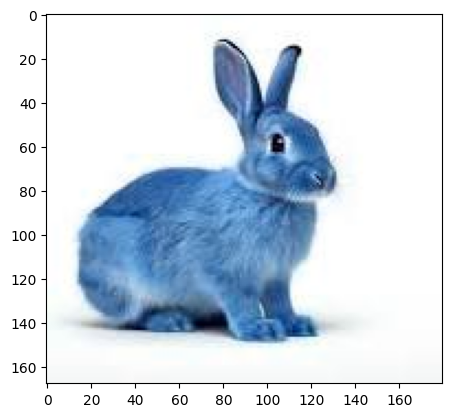

In [46]:
# Read the image from the specified file path
img = cv2.imread(image_path)
plt.imshow(img)

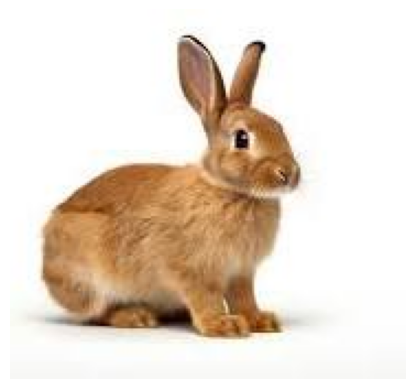

In [47]:

# Convert OpenCV's BGR format to RGBbcz Matplotlib expects images in RGB format
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Display the image
plt.imshow(img_rgb)
plt.axis('off')
plt.show()

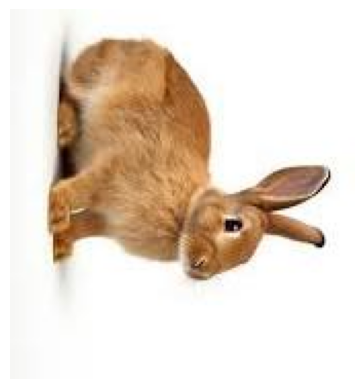

In [48]:
rotated = cv2.rotate(img_rgb, cv2.ROTATE_90_CLOCKWISE)
plt.imshow(rotated)
plt.axis('off')
plt.show()

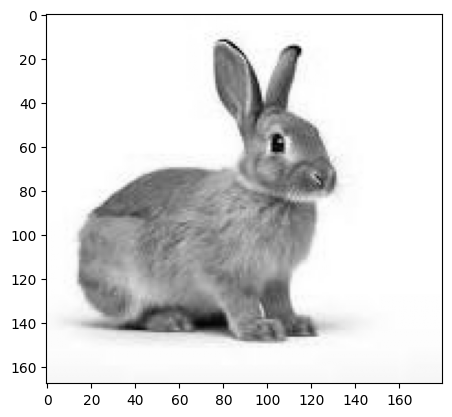

In [52]:
#Convert the input image to grayscale.
gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
plt.imshow(gray,cmap='gray')       # cmap='gray' is used  to display an image using grayscale shades(black,white,& grey shades) It affects visualization, not the actual image data


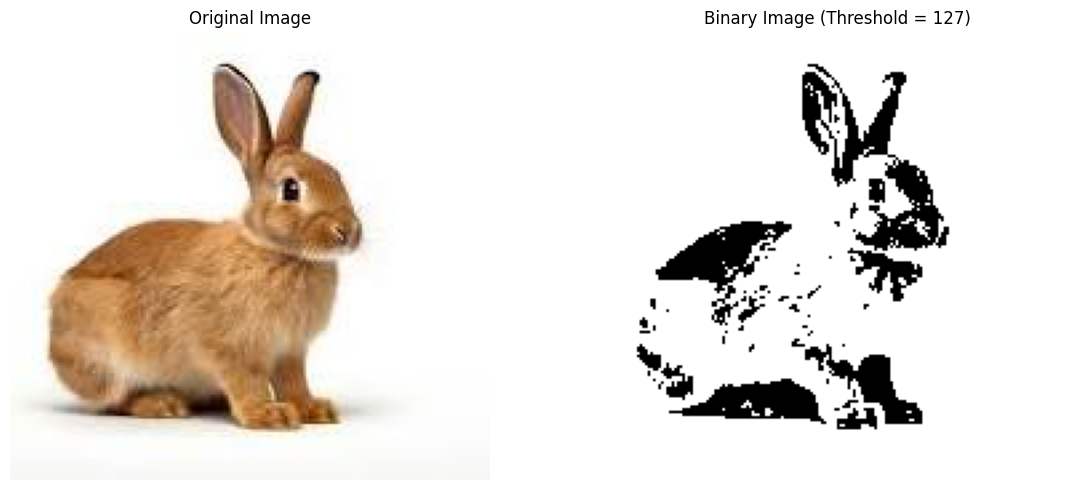

In [55]:
# Apply Binary Thresholding
_, thresh = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

# Display Original and Binary images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(thresh, cmap="gray")
plt.title("Binary Image (Threshold = 127)")
plt.axis("off")

plt.tight_layout()
plt.show()


In [56]:
flower_path= "/content/drive/MyDrive/Computer Vision/flower.jpg"

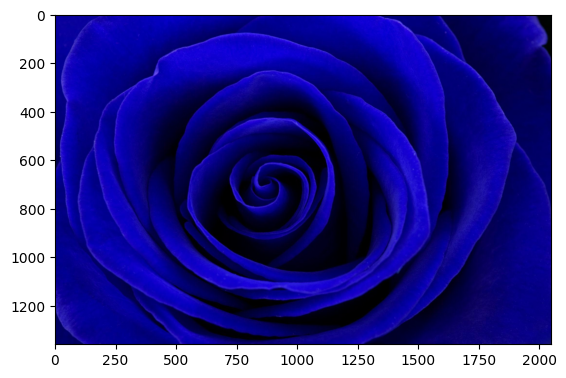

In [57]:
img=cv2.imread(flower_path)
plt.imshow(img)             #Image in BGR Format by default

(np.float64(-0.5), np.float64(2047.5), np.float64(1359.5), np.float64(-0.5))

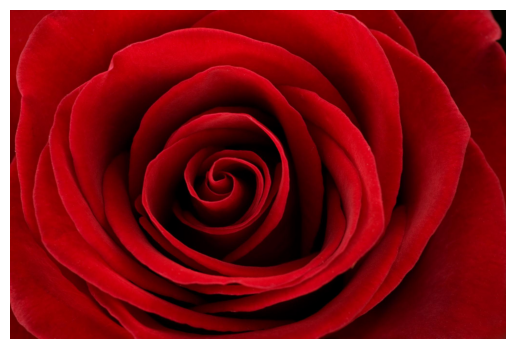

In [58]:
#Convert it in RGB format

img_rgb=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.axis("off")

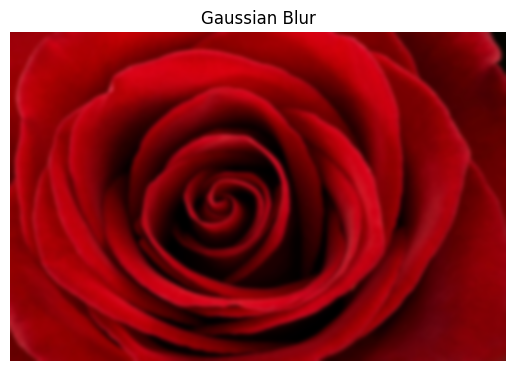

In [12]:
#Apply Gaussian smoothing with an 11×11 kernel.
blur = cv2.GaussianBlur(img_rgb, (51, 51), 0)

plt.imshow(blur)
plt.title("Gaussian Blur")
plt.axis("off")
plt.show()

In [13]:
cycle_path="/content/drive/MyDrive/Computer Vision/cycle.jpg"

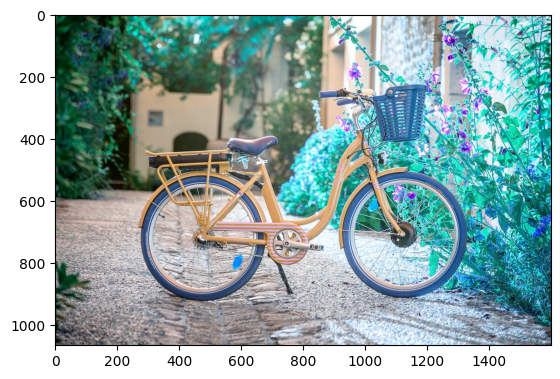

In [14]:
img=cv2.imread(cycle_path)
plt.imshow(img)             #Image in BGR Format by default

(np.float64(-0.5), np.float64(1599.5), np.float64(1064.5), np.float64(-0.5))

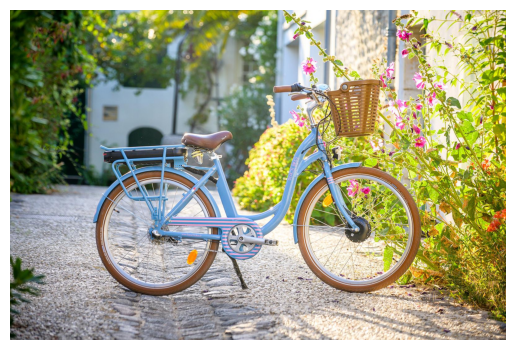

In [15]:
#Convert it in RGB format

img_rgb=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.axis("off")

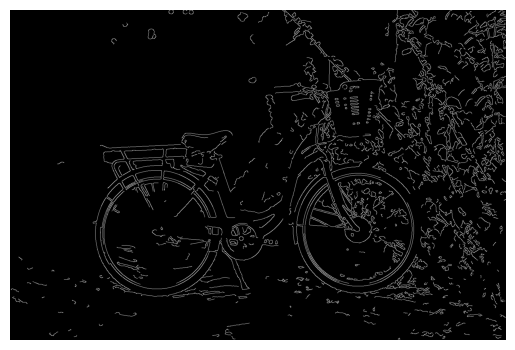

In [16]:
#detect edges using canny

# Step 1: Convert to Grayscale
gray = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2GRAY)

# Step 2: Apply Gaussian Blur before Canny to remove background noise (like grass and texture details) bcz
# Canny is highly sensitive and detects every minor change; blurring smooths out unwanted details
# so the algorithm focuses only on the main object's edges. (sigmaX=0 lets OpenCV calculate deviation automatically)
blurred = cv2.GaussianBlur(gray, (9, 9), 0)

# Step 3: Apply Canny on the blurred image
edges = cv2.Canny(blurred, 100, 200)

plt.imshow(edges, cmap="gray")
plt.axis("off")
plt.show()

##Why convert to grey scale?
1.Canny Edge Detection ya Thresholding ke liye Zaroori:

Canny Edge Detector ma algorithm ko sirf yeh dekhna hota hai ke kahan brightness tezi se change ho rahi hai. Uske liye color (Red, Green, Blue) ki koi zaroorat nahi hoti, sirf light ki intensity (intensity changes) chahiye hoti hain.

2.Background se Object Alag Karna (Thresholding):

Jab humein binary image (Strict Black & White) banani hoti hai, toh color image par threshold lagana mushkil hota hai kyunke har color ka apna combination hota hai. Grayscale mein har pixel 0 (black) se 255 (white) tak ki ek hi single value rakhta hai, jis ki wajah se thresholding aur filtering bohot asan ho jati hai

In [62]:
image_path2 = "/content/drive/MyDrive/Computer Vision/baby.png"

In [63]:
# Read image
img = cv2.imread(image_path2)  #BGR

In [64]:
img_rgb=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

In [65]:
gray = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2GRAY)

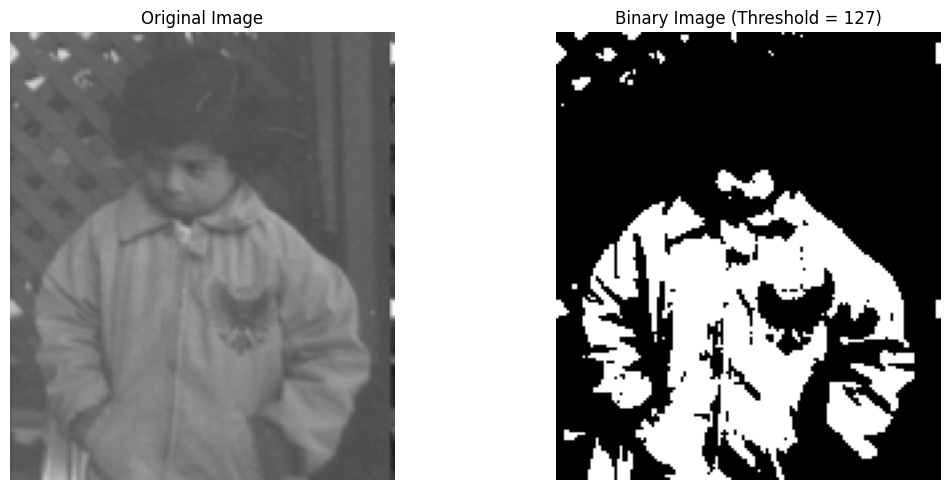

In [66]:
# Apply Binary Thresholding
_, thresh = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)
# Display Original and Binary images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(thresh, cmap="gray")
plt.title("Binary Image (Threshold = 127)")
plt.axis("off")

plt.tight_layout()
plt.show()


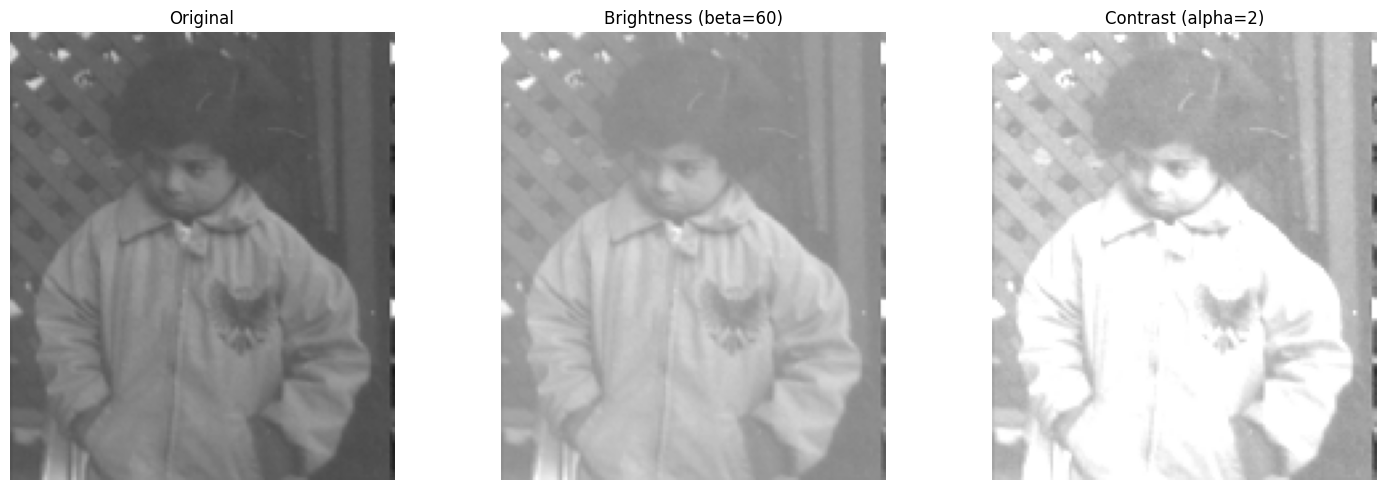

In [69]:
# Apply brightness adjustment
bright = cv2.convertScaleAbs(img_rgb, alpha=1, beta=60) # beta is for brightness (intensity shifting,  add beta in intensity values).

# Apply contrast adjustment
contrast = cv2.convertScaleAbs(img_rgb, alpha=2, beta=0)     #alpha is for contrast (intensity scaling, multiply alpha by intensity values)

# Display comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(bright)
plt.title("Brightness (beta=60)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(contrast)
plt.title("Contrast (alpha=2)")
plt.axis("off")

plt.tight_layout()
plt.show()

#Question # 2 (Practical Tasks)

In [32]:
image_path = "/content/drive/MyDrive/Computer Vision/rabbit.jpg"

In [33]:
# Read the image from the specified file path
img = cv2.imread(image_path)


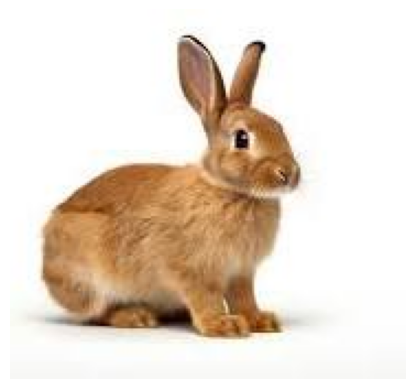

In [34]:

# Convert OpenCV's BGR format to RGBbcz Matplotlib expects images in RGB format
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Display the image
plt.imshow(img_rgb)
plt.axis('off')
plt.show()

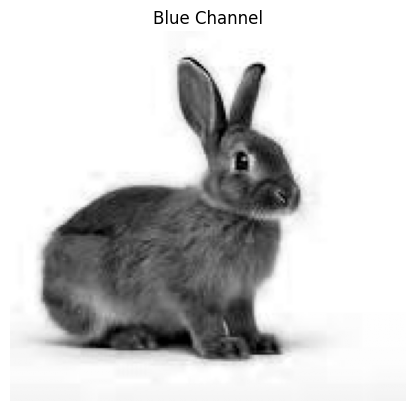

In [35]:

# Extract only the Blue channel
# Channel 0 represents Blue in OpenCV's BGR format, while channel 2 represents Blue in RGB format..  (R(0),G(1),B(2)  in RGB Format)
blue_channel = img_rgb[:, :, 2]

# Display the Blue channel as a grayscale intensity image
plt.imshow(blue_channel, cmap='gray')
plt.title('Blue Channel')
plt.axis('off')
plt.show()

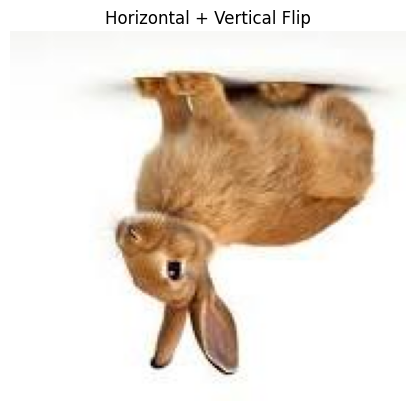

In [36]:
# Flip the image both horizontally and vertically
# flipCode = -1 performs both flips simultaneously
flip_both = cv2.flip(img_rgb, -1)

# Display the result
plt.imshow(flip_both)
plt.title('Horizontal + Vertical Flip')
plt.axis('off')
plt.show()

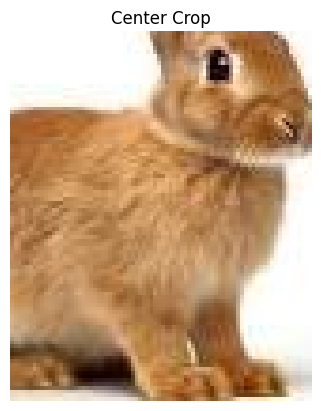

In [37]:
# Get image dimensions
h, w, _ = img_rgb.shape


center_crop = img_rgb[50:h-20, 50:w-50]

plt.imshow(center_crop)
plt.title("Center Crop")
plt.axis("off")
plt.show()

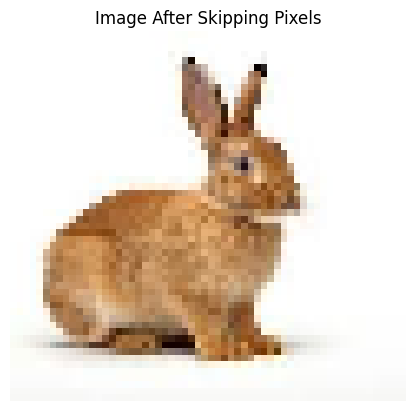

In [38]:
# Take every third pixel along rows and columns
# This reduces the number of pixels in the image
skip_3rd = img_rgb[::3, ::3]

# Display the reduced image
plt.imshow(skip_3rd)
plt.title('Image After Skipping Pixels')
plt.axis('off')
plt.show()

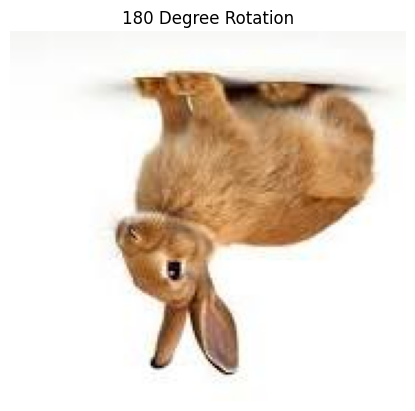

In [39]:
# Rotate the image by 180 degrees
rotated_180 = img_rgb[::-1, ::-1, :]

# Display rotated image
plt.imshow(rotated_180)
plt.title('180 Degree Rotation')
plt.axis('off')
plt.show()

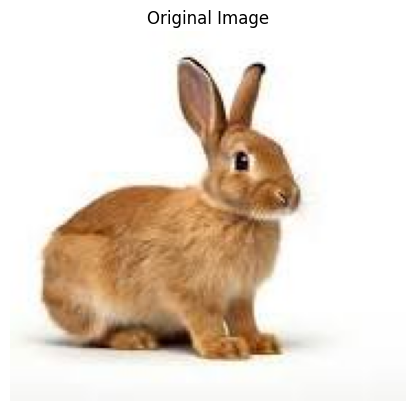

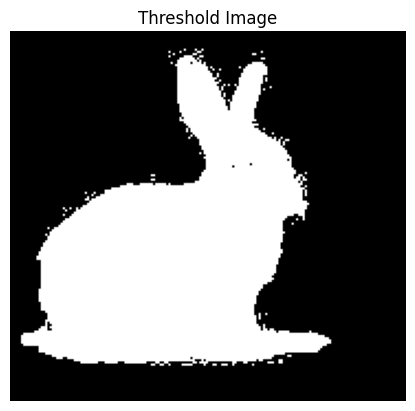

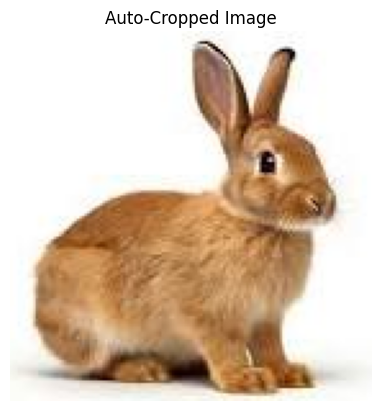

In [22]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Read image
img = cv2.imread(image_path)

# Convert BGR to RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) #See grayscale img

# Get border pixels
border = np.concatenate([
    gray[0, :],     # top row
    gray[-1, :],    # bottom row
    gray[:, 0],     # left column
    gray[:, -1]     # right column
])

# Find average brightness of background
background = np.mean(border)

# Threshold image
if background > 245:
    _, thresh = cv2.threshold(
        gray,
        245,
        255,
        cv2.THRESH_BINARY_INV
    )
else:
    _, thresh = cv2.threshold(
        gray,
        245,
        255,
        cv2.THRESH_BINARY
    )
#extract object using np.where
# Find row and column positions of the object
r, c = np.where(thresh > 0) #light object

if len(r) > 0:

    # Find minimum and maximum row
    min_r = np.min(r)
    max_r = np.max(r)

    # Find minimum and maximum column
    min_c = np.min(c)
    max_c = np.max(c)
    #crop object using min and max
    # Crop using row and column positions
    cropped = img_rgb[min_r:max_r+1, min_c:max_c+1] #Python slicing does not include the ending index.

    # Display original
    plt.imshow(img_rgb)
    plt.title('Original Image')
    plt.axis('off')
    plt.show()

    # Display threshold
    plt.imshow(thresh, cmap='gray')
    plt.title('Threshold Image')
    plt.axis('off')
    plt.show()

    # Display cropped image
    plt.imshow(cropped)
    plt.title('Auto-Cropped Image')
    plt.axis('off')
    plt.show()

else:
    print("No object detected.")

In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
image_path1 = "/content/drive/MyDrive/Computer Vision/3objects.png"

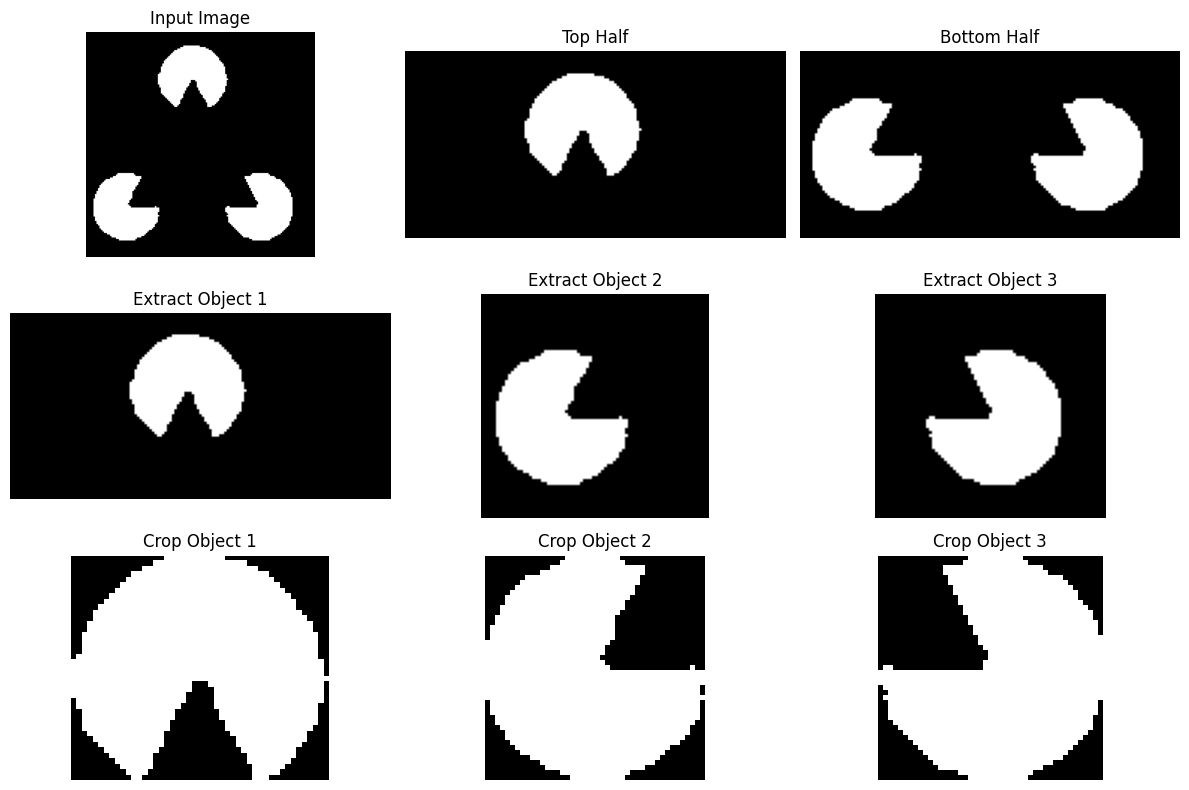

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread(image_path1)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# Binary image
_, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)

rows, cols = binary.shape

# --------------------------
# SPLITTING
# --------------------------

row_mid = rows // 2

top_half = binary[:row_mid, :]
bottom_half = binary[row_mid:, :]

col_mid = cols // 2

left_half = bottom_half[:, :col_mid]
right_half = bottom_half[:, col_mid:]

# FUNCTION TO EXTRACT OBJECT


def extract_roi(part):

    r, c = np.where(part > 0)

    min_r = np.min(r)
    max_r = np.max(r)

    min_c = np.min(c)
    max_c = np.max(c)

    # Cropped ROI
    crop = part[min_r:max_r+1, min_c:max_c+1]

    # Same size image with object only
    obj = np.zeros_like(part)
    obj[min_r:max_r+1, min_c:max_c+1] = crop

    return obj, crop

# Extract objects
obj1, crop1 = extract_roi(top_half)
obj2, crop2 = extract_roi(left_half)
obj3, crop3 = extract_roi(right_half)

# --------------------------
# DISPLAY
# --------------------------

plt.figure(figsize=(12,8))

# Row 1
plt.subplot(3,3,1)
plt.imshow(binary, cmap='gray')
plt.title("Input Image")
plt.axis('off')

plt.subplot(3,3,2)
plt.imshow(top_half, cmap='gray')
plt.title("Top Half")
plt.axis('off')

temp = np.hstack((left_half, right_half))
plt.subplot(3,3,3)
plt.imshow(temp, cmap='gray')
plt.title("Bottom Half")
plt.axis('off')

# Row 2
plt.subplot(3,3,4)
plt.imshow(obj1, cmap='gray')
plt.title("Extract Object 1")
plt.axis('off')

plt.subplot(3,3,5)
plt.imshow(obj2, cmap='gray')
plt.title("Extract Object 2")
plt.axis('off')

plt.subplot(3,3,6)
plt.imshow(obj3, cmap='gray')
plt.title("Extract Object 3")
plt.axis('off')

# Row 3 (Cropped)
plt.subplot(3,3,7)
plt.imshow(crop1, cmap='gray')
plt.title("Crop Object 1")
plt.axis('off')

plt.subplot(3,3,8)
plt.imshow(crop2, cmap='gray')
plt.title("Crop Object 2")
plt.axis('off')

plt.subplot(3,3,9)
plt.imshow(crop3, cmap='gray')
plt.title("Crop Object 3")
plt.axis('off')

plt.tight_layout()
plt.show()

In [26]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [87]:
image_path2 = "/content/drive/MyDrive/Computer Vision/baby.png"

Image Type: RGB
Mean Intensity: 109.84888798204447
Contrast: 23.70682271981166
Image Issue: Low Contrast


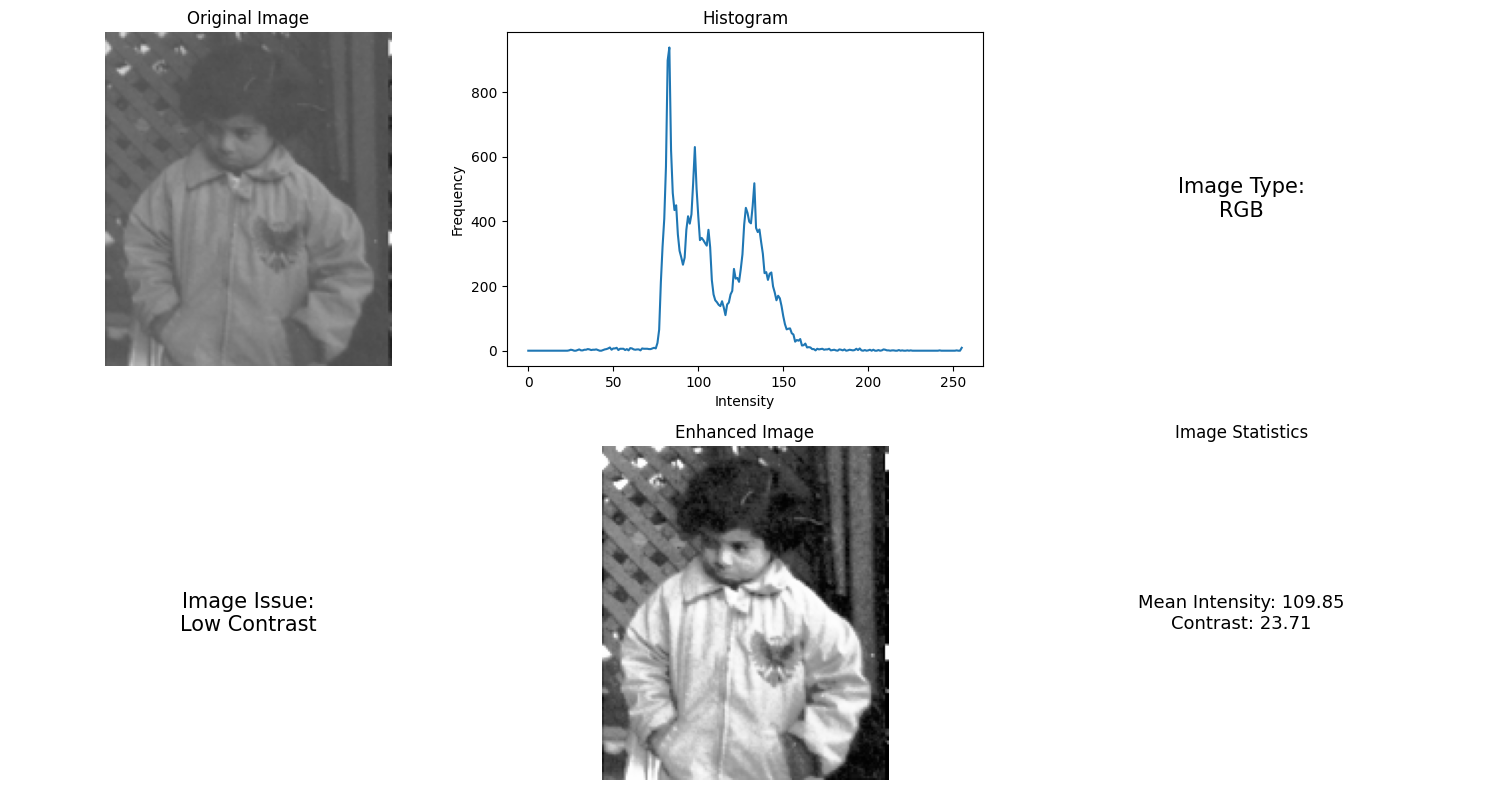

In [88]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Read image
img = cv2.imread(image_path2)

# -----------------------------
# 1. FIND IMAGE TYPE
# -----------------------------

# Convert BGR to RGB
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Check number of channels
if len(img.shape) == 2:

    image_type = "Binary or Grayscale"

    # Find unique pixel values
    unique_values = np.unique(img)

    # Check whether values are only 0 or 255
    if np.all(np.isin(unique_values, [0, 255])):
        image_type = "Binary"
    else:
        image_type = "Grayscale"

else:
    image_type = "RGB"

print("Image Type:", image_type)


# 2. FIND IMAGE ISSUE

# Convert image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Calculate histogram
histogram = cv2.calcHist(
    [gray],
    [0],
    None,
    [256],
    [0, 256]
)

# Calculate mean intensity / brightness
mean_intensity = np.mean(gray)

# Calculate standard deviation / contrast
contrast = np.std(gray)

print("Mean Intensity:", mean_intensity)
print("Contrast:", contrast)


# Find image problem
if mean_intensity < 70:
    issue = "Over Dark"

elif mean_intensity > 180:
    issue = "Over Bright"

elif contrast < 40:
    issue = "Low Contrast"

else:
    issue = "Normal"

print("Image Issue:", issue)


# -----------------------------
# 3. ENHANCE IMAGE
# -----------------------------

if issue == "Over Dark":

    # Increase brightness
    enhanced = cv2.convertScaleAbs(
        rgb,
        alpha=1.2,
        beta=60
    )

elif issue == "Over Bright":

    # Decrease brightness
    enhanced = cv2.convertScaleAbs(
        rgb,
        alpha=1.0,
        beta=-60
    )

elif issue == "Low Contrast":

    # Improve contrast using histogram equalization
    enhanced_gray = cv2.equalizeHist(gray)

    # Convert grayscale result to RGB
    enhanced = cv2.cvtColor(
        enhanced_gray,
        cv2.COLOR_GRAY2RGB
    )

else:

    # No enhancement required
    enhanced = rgb


# -----------------------------
# 4. SHOW ALL RESULTS
# -----------------------------

plt.figure(figsize=(15, 8))

# Original image
plt.subplot(2, 3, 1)
plt.imshow(rgb)
plt.title("Original Image")
plt.axis("off")

# Histogram
plt.subplot(2, 3, 2)
plt.plot(histogram)
plt.title("Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

# Image Type
plt.subplot(2, 3, 3)
plt.text(
    0.5,
    0.5,
    "Image Type:\n" + image_type,
    ha="center",
    va="center",
    fontsize=15
)
plt.axis("off")

# Image Issue
plt.subplot(2, 3, 4)
plt.text(
    0.5,
    0.5,
    "Image Issue:\n" + issue,
    ha="center",
    va="center",
    fontsize=15
)
plt.axis("off")

# Enhanced Image
plt.subplot(2, 3, 5)
plt.imshow(enhanced)
plt.title("Enhanced Image")
plt.axis("off")

# Mean and contrast
plt.subplot(2, 3, 6)
plt.text(
    0.5,
    0.5,
    "Mean Intensity: {:.2f}\nContrast: {:.2f}".format(
        mean_intensity,
        contrast
    ),
    ha="center",
    va="center",
    fontsize=13
)
plt.title("Image Statistics")
plt.axis("off")

plt.tight_layout()
plt.show()

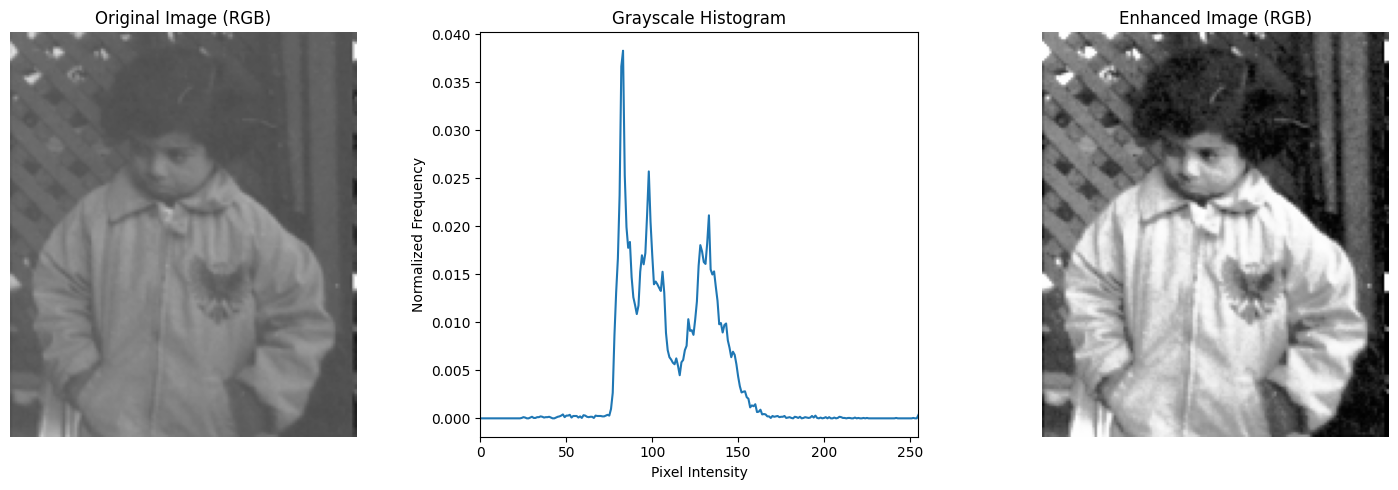

Image Type: RGB
Detected Issue: Low Contrast
Mean Brightness: 109.85
Dark Pixels (%): 3.42
Bright Pixels (%): 0.38
Contrast Range (1-99%): 83


In [89]:
#purely Using Histogram


# TASK (a): DETECT IMAGE TYPE


import cv2
import numpy as np
import matplotlib.pyplot as plt


# 1. READ IMAGE

img = cv2.imread(image_path2)

if img is None:
    raise ValueError("Image not found. Please check the image path.")


# 2. DETECT IMAGE TYPE


# Convert image into grayscale for intensity analysis
if len(img.shape) == 2:
    gray = img.copy()
else:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Detect binary, grayscale, or RGB type
# Here, two unique grayscale intensities are treated
unique_values = np.unique(gray)

if len(unique_values) == 2:
    image_type = "Binary"

elif len(img.shape) == 2:
    image_type = "Grayscale"

else:
    image_type = "RGB"

# Convert original image to RGB
if len(img.shape) == 2:
    original = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
else:
    original = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# TASK (b): DETECT IMAGE ISSUE USING HISTOGRAM

# 3. HISTOGRAM ANALYSIS


# Calculate the frequency of each grayscale intensity
hist = cv2.calcHist(
    [gray], [0], None, [256], [0, 256]
).flatten()

# Normalize histogram to calculate pixel proportions
hist = hist / hist.sum()

# Calculate percentage of dark and bright pixels
# Dark: intensities 0-79
# Bright: intensities 176-255
dark_percent = hist[:80].sum() * 100
bright_percent = hist[176:].sum() * 100

# Mean intensity represents average image brightness
mean_intensity = np.mean(gray)

# Calculate contrast range using 1st and 99th percentiles
# This reduces the influence of extreme pixel values
cdf = np.cumsum(hist)

low_p = np.searchsorted(cdf, 0.01)
high_p = np.searchsorted(cdf, 0.99)

contrast_range = high_p - low_p          #if low_p=65 and high_p=148, that means majority pixels 65 se 148 ke darmiyan concentrated hain.

# 4. DETECT IMAGE ISSUE


# These are example thresholds.
# Test them on the provided images and adjust if needed.

if image_type == "Binary":
    issue = "Binary Image (Enhancement Skipped)"

elif mean_intensity < 70 and dark_percent > 50:
    issue = "Over Dark"

elif mean_intensity > 180 and bright_percent > 50:
    issue = "Over Bright"

elif contrast_range < 100:
    issue = "Low Contrast"

else:
    issue = "Normal"



# TASK (c): RESOLVE THE DETECTED ISSUE

# Start with original colored RGB image
enhanced = original.copy()

if issue == "Over Dark":

    # Gamma < 1 brightens the image
    gamma = 0.6

    normalized = original.astype(np.float32) / 255.0

    enhanced = np.power(normalized, gamma) * 255

# Clip pixel values to the valid range (0–255) because
# gamma correction may produce values outside this range.
# Values below 0 become 0, values above 255 become 255,
# and values within the range remain unchanged.
    enhanced = np.clip(
        enhanced, 0, 255
    ).astype(np.uint8)


elif issue == "Over Bright":

    # Gamma > 1 darkens the image
    gamma = 1.5

    normalized = original.astype(np.float32) / 255.0

    enhanced = np.power(normalized, gamma) * 255

    enhanced = np.clip(
        enhanced, 0, 255
    ).astype(np.uint8)


elif issue == "Low Contrast":

    # Apply histogram equalization on grayscale
    enhanced_gray = cv2.equalizeHist(gray)

    # Convert enhanced grayscale to RGB
    enhanced = cv2.cvtColor(
        enhanced_gray, cv2.COLOR_GRAY2RGB
    )


elif issue == "Normal":

    # No enhancement required
    enhanced = original.copy()


elif issue == "Binary Image (Enhancement Skipped)":

    # Preserve original image
    enhanced = original.copy()



# TASK (d): TEST THE PROVIDED IMAGES and show results



plt.figure(figsize=(15, 5))

# Original colored RGB image
plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image (RGB)")
plt.axis("off")

# Grayscale histogram
plt.subplot(1, 3, 2)
plt.plot(hist)
plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Normalized Frequency")
plt.xlim(0, 255)

# Enhanced image
plt.subplot(1, 3, 3)
plt.imshow(enhanced)
plt.title("Enhanced Image (RGB)")
plt.axis("off")

plt.tight_layout()
plt.show()

# Display image information
print("Image Type:", image_type)
print("Detected Issue:", issue)
print("Mean Brightness:", round(mean_intensity, 2))
print("Dark Pixels (%):", round(dark_percent, 2))
print("Bright Pixels (%):", round(bright_percent, 2))
print("Contrast Range (1-99%):", contrast_range)



In [84]:
bright = "/content/drive/MyDrive/Computer Vision/Bright.png"

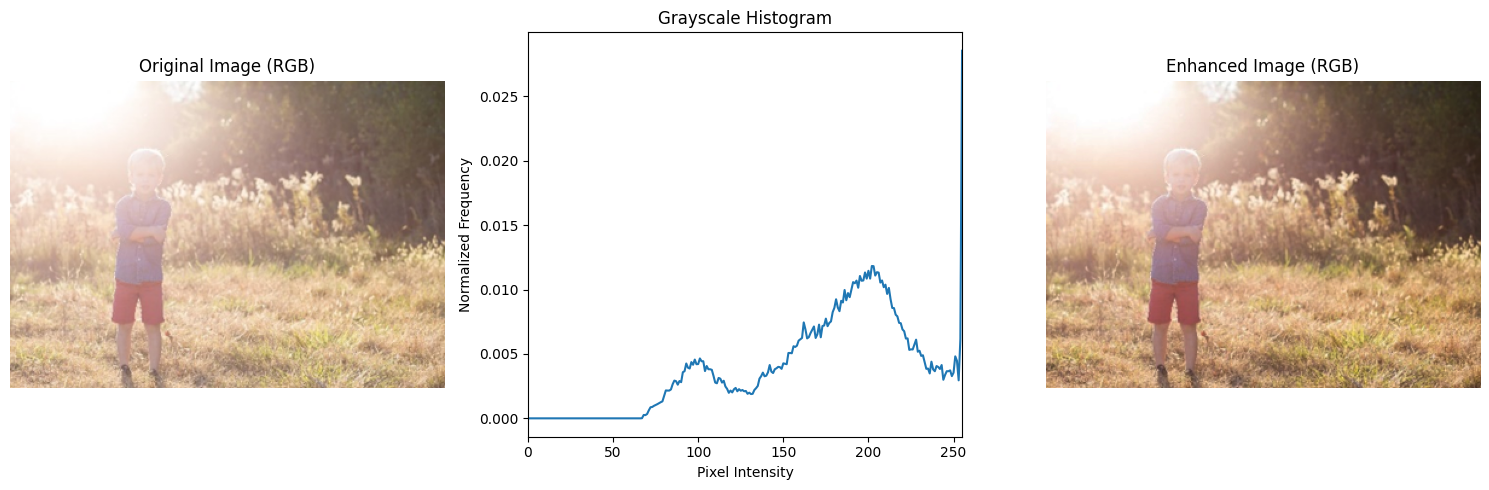

Image Type: RGB
Detected Issue: Over Bright
Mean Brightness: 180.78
Dark Pixels (%): 1.01
Bright Pixels (%): 61.53
Contrast Range (1-99%): 176


In [86]:

# ==========================================
# TASK (a): DETECT IMAGE TYPE
# ==========================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. READ IMAGE
# ------------------------------------------

img = cv2.imread(bright)

# Check whether image was loaded successfully
if img is None:
    raise ValueError("Image not found. Please check the image path.")

# ------------------------------------------
# 2. DETECT IMAGE TYPE
# ------------------------------------------

# Convert image into grayscale for intensity analysis
if len(img.shape) == 2:
    gray = img.copy()
else:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Detect binary, grayscale, or RGB type
# Here, two unique grayscale intensities are treated
# as a binary-valued image (simplified lab rule).
unique_values = np.unique(gray)

if len(unique_values) == 2:
    image_type = "Binary"

elif len(img.shape) == 2:
    image_type = "Grayscale"

else:
    image_type = "RGB"

# Convert original image to RGB for correct display
if len(img.shape) == 2:
    original = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
else:
    original = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# ==========================================
# TASK (b): DETECT IMAGE ISSUE USING HISTOGRAM
# ==========================================

# ------------------------------------------
# 3. HISTOGRAM ANALYSIS
# ------------------------------------------

# Calculate the frequency of each grayscale intensity
hist = cv2.calcHist(
    [gray], [0], None, [256], [0, 256]
).flatten()

# Normalize histogram to calculate pixel proportions
hist = hist / hist.sum()

# Calculate percentage of dark and bright pixels
# Dark: intensities 0-79
# Bright: intensities 176-255
dark_percent = hist[:80].sum() * 100
bright_percent = hist[176:].sum() * 100

# Mean intensity represents average image brightness
mean_intensity = np.mean(gray)

# Calculate contrast range using 1st and 99th percentiles
# This reduces the influence of extreme pixel values
cdf = np.cumsum(hist)

low_p = np.searchsorted(cdf, 0.01)
high_p = np.searchsorted(cdf, 0.99)

contrast_range = high_p - low_p          #if low_p=65 and high_p=148, that means majority pixels 65 se 148 ke darmiyan concentrated hain.

# ------------------------------------------
# 4. DETECT IMAGE ISSUE
# ------------------------------------------

# These are example thresholds.
# Test them on the provided images and adjust if needed.

if image_type == "Binary":
    issue = "Binary Image (Enhancement Skipped)"

elif mean_intensity < 70 and dark_percent > 50:
    issue = "Over Dark"

elif mean_intensity > 180 and bright_percent > 50:
    issue = "Over Bright"

elif contrast_range < 100:
    issue = "Low Contrast"

else:
    issue = "Normal"



# ==========================================
# TASK (c): RESOLVE THE DETECTED ISSUE
# ==========================================

# Start with original colored RGB image
enhanced = original.copy()

if issue == "Over Dark":

    # Gamma < 1 brightens the image
    gamma = 0.6

    normalized = original.astype(np.float32) / 255.0

    enhanced = np.power(normalized, gamma) * 255

    enhanced = np.clip(
        enhanced, 0, 255
    ).astype(np.uint8)


elif issue == "Over Bright":

    # Gamma > 1 darkens the image
    gamma = 1.5

    normalized = original.astype(np.float32) / 255.0

    enhanced = np.power(normalized, gamma) * 255

    enhanced = np.clip(
        enhanced, 0, 255
    ).astype(np.uint8)


elif issue == "Low Contrast":

    # Apply histogram equalization on grayscale
    enhanced_gray = cv2.equalizeHist(gray)

    # Convert enhanced grayscale to RGB
    enhanced = cv2.cvtColor(
        enhanced_gray, cv2.COLOR_GRAY2RGB
    )


elif issue == "Normal":

    # No enhancement required
    enhanced = original.copy()


elif issue == "Binary Image (Enhancement Skipped)":

    # Preserve original image
    enhanced = original.copy()



# ==========================================
# TASK (d): TEST THE PROVIDED IMAGES and show results
# ==========================================



plt.figure(figsize=(15, 5))

# Original colored RGB image
plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image (RGB)")
plt.axis("off")

# Grayscale histogram
plt.subplot(1, 3, 2)
plt.plot(hist)
plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Normalized Frequency")
plt.xlim(0, 255)

# Enhanced image
plt.subplot(1, 3, 3)
plt.imshow(enhanced)
plt.title("Enhanced Image (RGB)")
plt.axis("off")

plt.tight_layout()
plt.show()

# Display image information
print("Image Type:", image_type)
print("Detected Issue:", issue)
print("Mean Brightness:", round(mean_intensity, 2))
print("Dark Pixels (%):", round(dark_percent, 2))
print("Bright Pixels (%):", round(bright_percent, 2))
print("Contrast Range (1-99%):", contrast_range)



In [90]:
dark = "/content/drive/MyDrive/Computer Vision/dark.png"

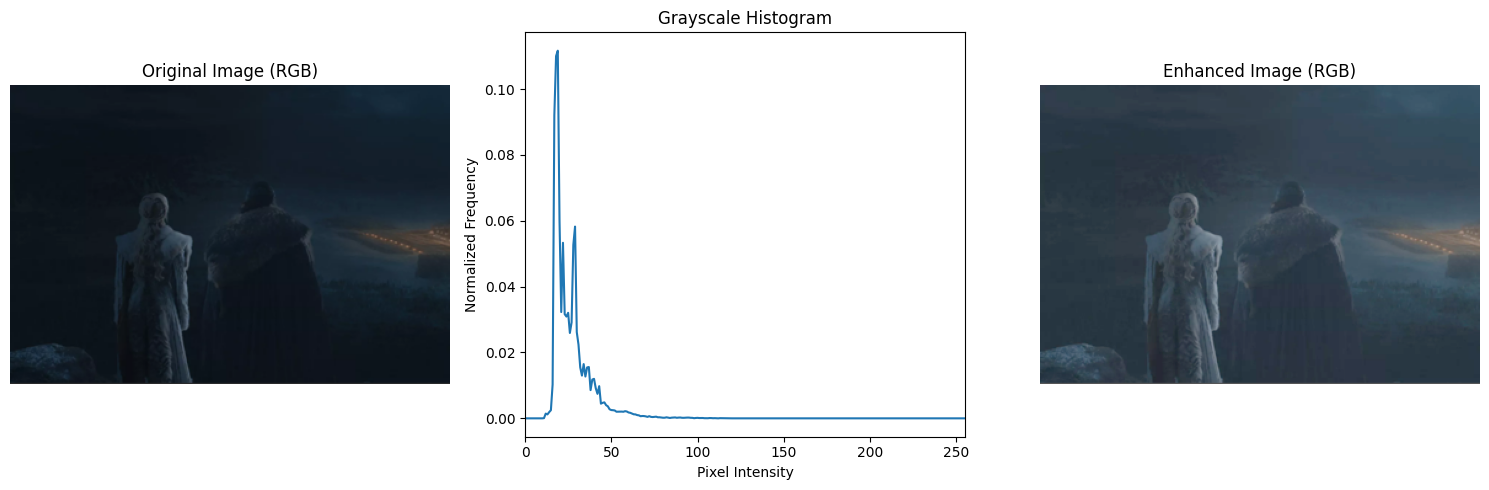

Image Type: RGB
Detected Issue: Over Dark
Mean Brightness: 26.59
Dark Pixels (%): 99.52
Bright Pixels (%): 0.0
Contrast Range (1-99%): 52


In [92]:

# ==========================================
# TASK (a): DETECT IMAGE TYPE
# ==========================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. READ IMAGE
# ------------------------------------------

img = cv2.imread(dark)

# Check whether image was loaded successfully
if img is None:
    raise ValueError("Image not found. Please check the image path.")

# ------------------------------------------
# 2. DETECT IMAGE TYPE
# ------------------------------------------

# Convert image into grayscale for intensity analysis
if len(img.shape) == 2:
    gray = img.copy()
else:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Detect binary, grayscale, or RGB type
# Here, two unique grayscale intensities are treated
# as a binary-valued image (simplified lab rule).
unique_values = np.unique(gray)

if len(unique_values) == 2:
    image_type = "Binary"

elif len(img.shape) == 2:
    image_type = "Grayscale"

else:
    image_type = "RGB"

# Convert original image to RGB for correct display
if len(img.shape) == 2:
    original = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
else:
    original = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# ==========================================
# TASK (b): DETECT IMAGE ISSUE USING HISTOGRAM
# ==========================================

# ------------------------------------------
# 3. HISTOGRAM ANALYSIS
# ------------------------------------------

# Calculate the frequency of each grayscale intensity
hist = cv2.calcHist(
    [gray], [0], None, [256], [0, 256]
).flatten()

# Normalize histogram to calculate pixel proportions
hist = hist / hist.sum()

# Calculate percentage of dark and bright pixels
# Dark: intensities 0-79
# Bright: intensities 176-255
dark_percent = hist[:80].sum() * 100
bright_percent = hist[176:].sum() * 100

# Mean intensity represents average image brightness
mean_intensity = np.mean(gray)

# Calculate contrast range using 1st and 99th percentiles
# This reduces the influence of extreme pixel values
cdf = np.cumsum(hist)

low_p = np.searchsorted(cdf, 0.01)
high_p = np.searchsorted(cdf, 0.99)

contrast_range = high_p - low_p          #if low_p=65 and high_p=148, that means majority pixels 65 se 148 ke darmiyan concentrated hain.

# ------------------------------------------
# 4. DETECT IMAGE ISSUE
# ------------------------------------------

# These are example thresholds.
# Test them on the provided images and adjust if needed.

if image_type == "Binary":
    issue = "Binary Image (Enhancement Skipped)"

elif mean_intensity < 70 and dark_percent > 50:
    issue = "Over Dark"

elif mean_intensity > 180 and bright_percent > 50:
    issue = "Over Bright"

elif contrast_range < 100:
    issue = "Low Contrast"

else:
    issue = "Normal"



# ==========================================
# TASK (c): RESOLVE THE DETECTED ISSUE
# ==========================================

# Start with original colored RGB image
enhanced = original.copy()

if issue == "Over Dark":

    # Gamma < 1 brightens the image
    gamma = 0.6

    normalized = original.astype(np.float32) / 255.0

    enhanced = np.power(normalized, gamma) * 255

    enhanced = np.clip(
        enhanced, 0, 255
    ).astype(np.uint8)


elif issue == "Over Bright":

    # Gamma > 1 darkens the image
    gamma = 1.5

    normalized = original.astype(np.float32) / 255.0

    enhanced = np.power(normalized, gamma) * 255

    enhanced = np.clip(
        enhanced, 0, 255
    ).astype(np.uint8)


elif issue == "Low Contrast":

    # Apply histogram equalization on grayscale
    enhanced_gray = cv2.equalizeHist(gray)

    # Convert enhanced grayscale to RGB
    enhanced = cv2.cvtColor(
        enhanced_gray, cv2.COLOR_GRAY2RGB
    )


elif issue == "Normal":

    # No enhancement required
    enhanced = original.copy()


elif issue == "Binary Image (Enhancement Skipped)":

    # Preserve original image
    enhanced = original.copy()



# ==========================================
# TASK (d): TEST THE PROVIDED IMAGES and show results
# ==========================================



plt.figure(figsize=(15, 5))

# Original colored RGB image
plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image (RGB)")
plt.axis("off")

# Grayscale histogram
plt.subplot(1, 3, 2)
plt.plot(hist)
plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Normalized Frequency")
plt.xlim(0, 255)

# Enhanced image
plt.subplot(1, 3, 3)
plt.imshow(enhanced)
plt.title("Enhanced Image (RGB)")
plt.axis("off")

plt.tight_layout()
plt.show()

# Display image information
print("Image Type:", image_type)
print("Detected Issue:", issue)
print("Mean Brightness:", round(mean_intensity, 2))
print("Dark Pixels (%):", round(dark_percent, 2))
print("Bright Pixels (%):", round(bright_percent, 2))
print("Contrast Range (1-99%):", contrast_range)

